In [78]:
# Instale através do requirements.txt: pip install -r requirements.txt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn as skl
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import tensorflow as tf
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense, Input
from keras.callbacks import EarlyStopping
from keras import regularizers
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from keras.optimizers import Adam

In [88]:
df = pd.read_csv('../data/base-sintetica.txt', 
                 sep='\t', 
                 comment='#', 
                 header=None, 
                 names=['x1', 'x2', 'target'])

In [95]:
X = df.drop(columns=['target'])
y = df['target'] - 1

X_train, X_test, y_train, y_test = skl.model_selection.train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model_reg = Sequential(
    [
        Input(shape=(X_train_scaled.shape[1],)),
        Dense(8, activation='relu'),
        Dense(15, activation='softmax')
    ]
)

model_reg.compile(
    optimizer=Adam(learning_rate=0.01),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_reg.summary()


Model: "sequential_34"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_81 (Dense)                │ (None, 8)              │            24 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_82 (Dense)                │ (None, 15)             │           135 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 159 (636.00 B)

 Trainable params: 159 (636.00 B)

 Non-trainable params: 0 (0.00 B)

In [96]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True
)

history = model_reg.fit(
    X_train_scaled,
    y_train,
    batch_size=16,
    epochs=100,
    validation_split=0.2,
    verbose=1,
    callbacks=[early_stop]
)

Epoch 1/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.2604 - loss: 2.5016 - val_accuracy: 0.2292 - val_loss: 2.3043
Epoch 2/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.3932 - loss: 1.9912 - val_accuracy: 0.2708 - val_loss: 1.8904
Epoch 3/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.4479 - loss: 1.5345 - val_accuracy: 0.4896 - val_loss: 1.5036
Epoch 4/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6771 - loss: 1.1995 - val_accuracy: 0.7396 - val_loss: 1.1813
Epoch 5/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8359 - loss: 0.9453 - val_accuracy: 0.9583 - val_loss: 0.9245
Epoch 6/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 4s 163ms/step - accuracy: 0.9661 - loss: 0.7579 - val_accuracy: 0.9792 - val_loss: 0.7446
Epoch 7/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9870 - loss: 0.6108 - val_accuracy: 1.0000 - val_loss: 0.6145
Epoch 8/100
24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9896 - loss: 0.4981 - val_accuracy: 1.0000

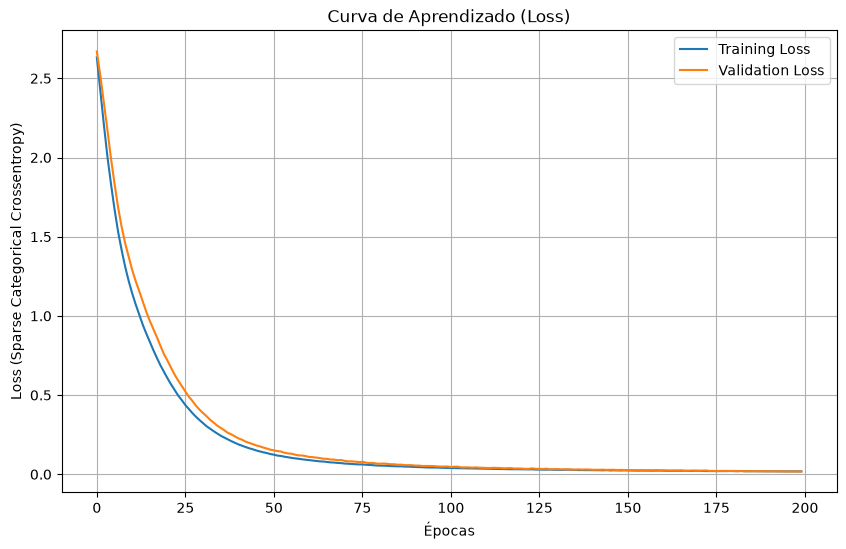

In [87]:
plt.figure(figsize=(10, 6))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Curva de Aprendizado (Loss)')
plt.xlabel('Épocas')
plt.ylabel('Loss (Sparse Categorical Crossentropy)')
plt.legend()
plt.grid(True)
plt.show()

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
Relatório de Classificação (Classes 0 a 14):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         8
           1       1.00      1.00      1.00         8
           2       1.00      1.00      1.00         8
           3       1.00      1.00      1.00         8
           4       1.00      1.00      1.00         8
           5       1.00      1.00      1.00         8
           6       1.00      1.00      1.00         8
           7       1.00      1.00      1.00         8
           8       1.00      1.00      1.00         8
           9       1.00      1.00      1.00         8
          10       1.00      1.00      1.00         8
          11       1.00      1.00      1.00         8
          12       1.00      1.00      1.00         8
          13       1.00      1.00      1.00         8
          14       1.00      1.00      1.00         8

    accuracy                           1.00       1

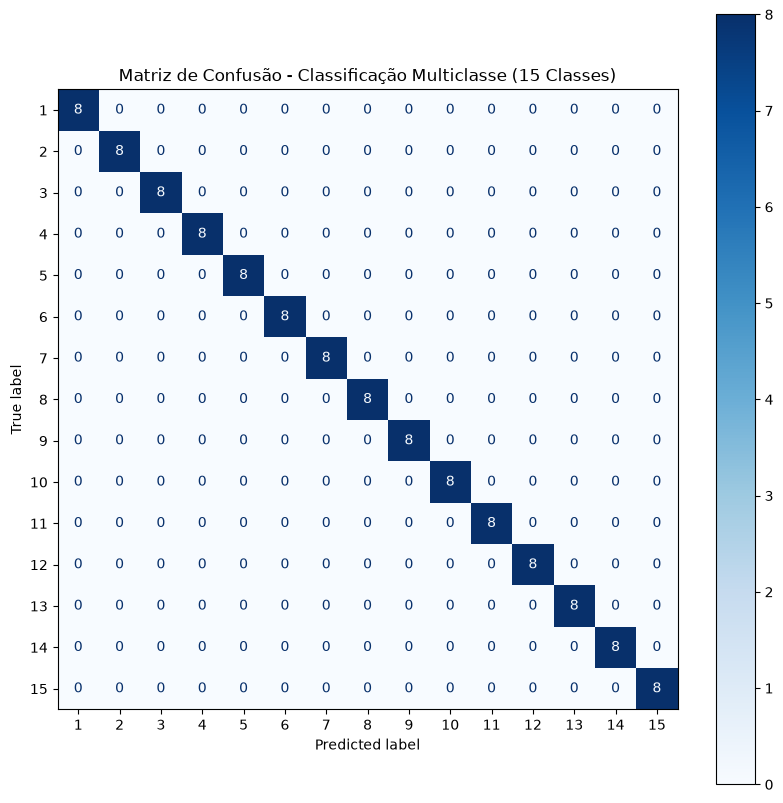

In [93]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

# 1. Gerar probabilidades para as 15 classes e selecionar a de maior valor
y_pred_prob = model_reg.predict(X_test_scaled)
y_pred = np.argmax(y_pred_prob, axis=1)

# 2. Exibir relatório completo (Precision, Recall/Sensitivity, F1-Score e Accuracy)
print("Relatório de Classificação (Classes 0 a 14):")
print(classification_report(y_test, y_pred))

# 3. Calcular e plotar a Matriz de Confusão 15x15
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(10, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=range(1, 16))
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title('Matriz de Confusão - Classificação Multiclasse (15 Classes)')
plt.show()